# Neural Network Python Project - Handwritten Digit Recognition

**Dataset:** MNIST Handwritten Digits  
**Source:** TensorFlow / Keras  
**Link:** https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist
 - The goal is to build a neural network that can recognize handwritten digits from 0 to 9.
- MNIST already has the images labeled and we can use the training data to teach the model and the test data to check how well it predicts digits it has not trained on.


In [58]:
%pip install --upgrade pip
%pip install -q numpy opencv-python matplotlib tensorflow


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [59]:
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


## 2. Load the MNIST dataset

TensorFlow already has MNIST in its Keras datasets, so we do not need to download a separate CSV file.

The dataset is split into:
- `Xtrain` and `ytrain`: images and labels used to train the model.
- `Xtest` and `ytest`: images and labels used to test the model.

`X` contains the image data and `y` contains the actual digit for each image.


In [60]:
mnist = tf.keras.datasets.mnist
(Xtrain, ytrain), (Xtest, ytest) = mnist.load_data()

### Inspect the image data

Each image is 28 rows by 28 columns. The pixel values are grayscale values from 0 to 255.

Start by looking at one image and its label.


Image shape: (28, 28) Image values: 0 Image maximum: 255 Image label: 5


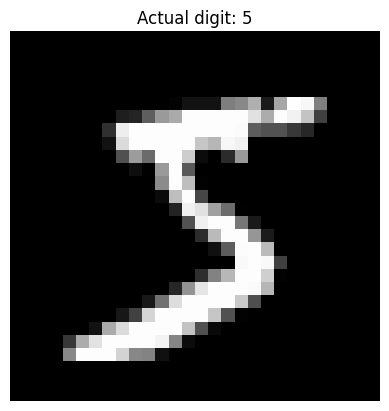

In [61]:
IMAGE_INDEX = 0

print("Image shape:", Xtrain[IMAGE_INDEX].shape,"Image values:", Xtrain[IMAGE_INDEX].min(),"Image maximum:", Xtrain[IMAGE_INDEX].max(),"Image label:", ytrain[IMAGE_INDEX])

plt.imshow(Xtrain[IMAGE_INDEX], cmap="gray")
plt.title(f"Actual digit: {ytrain[IMAGE_INDEX]}")
plt.axis("off")
plt.show()

### Look at multiple images

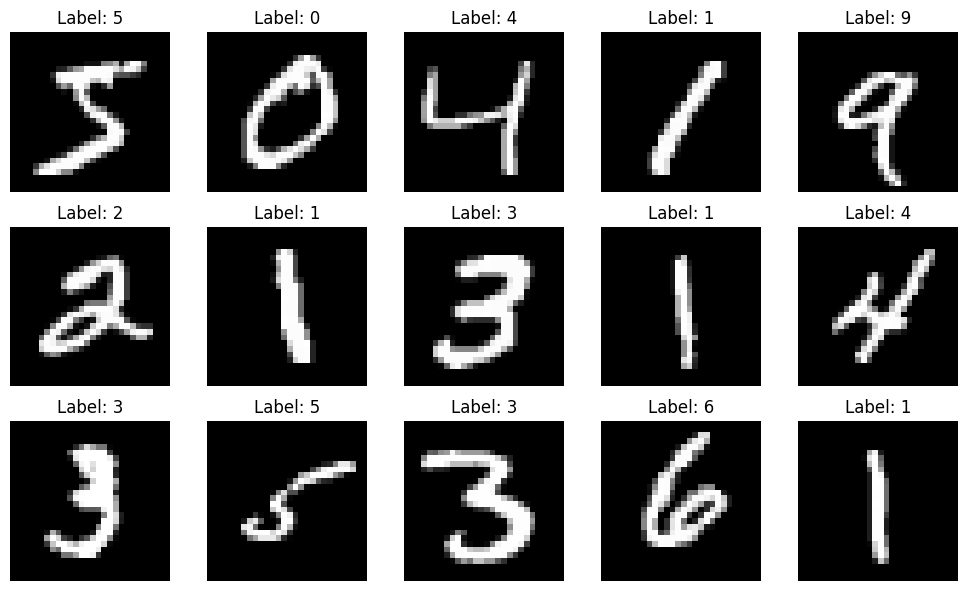

In [62]:
fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for index, ax in enumerate(axes.flat):
    ax.imshow(Xtrain[index], cmap="gray")
    ax.set_title(f"Label: {ytrain[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Prepare the data
### Normalize the pixel values
Divide by 255 so that every pixel is between 0 and 1.


In [63]:
Xtrain = Xtrain.astype("float32") / 255.0
Xtest = Xtest.astype("float32") / 255.0
print("Xtrain range:", Xtrain.min(), "to", Xtrain.max())
print("Xtest range: ", Xtest.min(), "to", Xtest.max())

Xtrain range: 0.0 to 1.0
Xtest range:  0.0 to 1.0


### Check the data

In [64]:
assert Xtrain.shape[1:] == (28, 28)
assert Xtest.shape[1:] == (28, 28)
assert len(Xtrain) == len(ytrain)
assert len(Xtest) == len(ytest)
assert np.isfinite(Xtrain).all()
assert np.isfinite(Xtest).all()
assert 0 <= Xtrain.min() and Xtrain.max() <= 1
assert 0 <= Xtest.min() and Xtest.max() <= 1
print("Training:", len(Xtrain))
print("Testing: ", len(Xtest))

Training: 60000
Testing:  10000


## 4. Build the neural network
- `Flatten` changes each 28 x 28 image into one row of 784 pixel values.
- The first `Dense` layer has 128 neurons and uses ReLU.
- The second `Dense` layer also has 128 neurons and uses ReLU.
- The output layer has 10 neurons, one for each digit from 0 to 9.
- Softmax gives the output probabilities for each digit.

In [65]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

In [66]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 5. Train the neural network
- An epoch is one complete pass through the training data.
- Start with 3 epochs. 
- The test data is passed as validation data so we can also see how the model performs on data it is not training on.


In [67]:
history = model.fit(
    Xtrain,
    ytrain,
    epochs=3,
    validation_data=(Xtest, ytest)
)

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9319 - loss: 0.2291 - val_accuracy: 0.9653 - val_loss: 0.1116
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9700 - loss: 0.0983 - val_accuracy: 0.9708 - val_loss: 0.0900
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9779 - loss: 0.0703 - val_accuracy: 0.9739 - val_loss: 0.0826


### Training accuracy and loss
Plot Graph


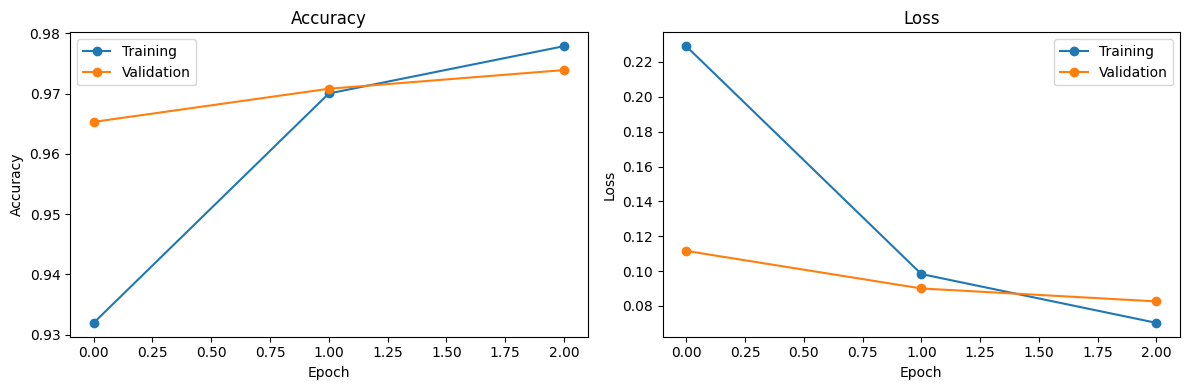

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], marker="o", label="Training")
axes[0].plot(history.history["val_accuracy"], marker="o", label="Validation")
axes[0].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend()
axes[1].plot(history.history["loss"], marker="o", label="Training")
axes[1].plot(history.history["val_loss"], marker="o", label="Validation")
axes[1].set(title="Loss", xlabel="Epoch", ylabel="Loss")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Save and reload

In [69]:
MODEL_PATH = Path("handwritten_digit_model.keras")
model.save(MODEL_PATH)
print("Saved model:", MODEL_PATH.resolve())

Saved model: C:\Users\James\Desktop\handwritten_digit_model.keras


### Load the saved model

In [70]:
model = tf.keras.models.load_model(MODEL_PATH)

## 7. Test the model

Use `evaluate` with the test data to get the final test loss and accuracy.

The test images were not used to update the model weights.


In [71]:
test_loss, test_accuracy = model.evaluate(Xtest, ytest, verbose=1)
print("Test loss:", round(float(test_loss), 4))
print("Test accuracy:", f"{test_accuracy:.2%}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - accuracy: 0.9739 - loss: 0.0826
Test loss: 0.0826
Test accuracy: 97.39%


### Predict one test image
- Start with one row from `Xtest`.
- The model returns 10 probabilities. 
- `argmax` gives the position of the largest probability, which is the predicted digit.

Predicted digit: 7
Actual digit:    7
Confidence:      99.95%


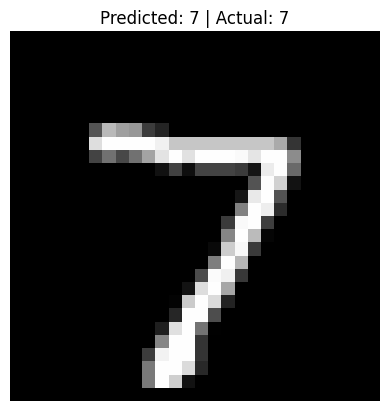

In [72]:
TEST_INDEX = 0
prediction = model.predict(Xtest[TEST_INDEX:TEST_INDEX + 1], verbose=0)[0]
predicted_digit = int(np.argmax(prediction))
print("Predicted digit:", predicted_digit)
print("Actual digit:   ", ytest[TEST_INDEX])
print("Confidence:     ", f"{np.max(prediction):.2%}")
plt.imshow(Xtest[TEST_INDEX], cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {ytest[TEST_INDEX]}")
plt.axis("off")
plt.show()

### Repeat for multiple test images

Check a group of test images and compare the predicted digit with the actual label.


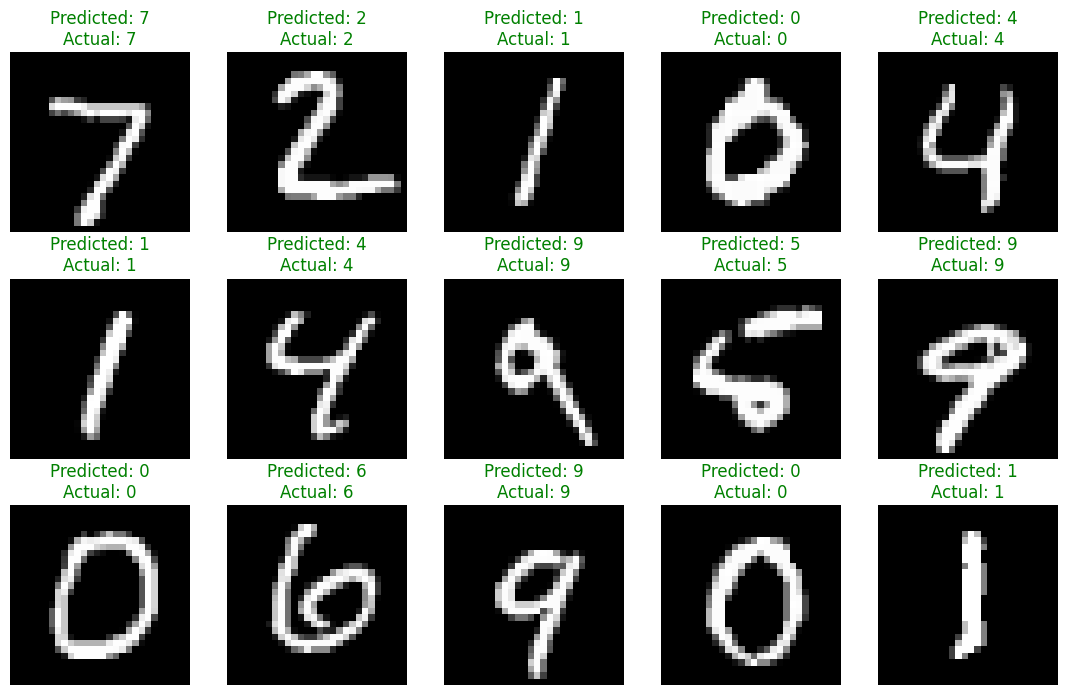

Number of predictions: 15
Correct predictions: 15


In [73]:
TEST_COUNT = 15
predictions = model.predict(Xtest[:TEST_COUNT], verbose=0)
predicted_digits = np.argmax(predictions, axis=1)
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for index, ax in enumerate(axes.flat):
    predicted = int(predicted_digits[index])
    actual = int(ytest[index])
    color = "green" if predicted == actual else "red"
    ax.imshow(Xtest[index], cmap="gray")
    ax.set_title(
        f"Predicted: {predicted}\nActual: {actual}",
        color=color
    )
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Number of predictions:", len(predicted_digits))
print("Correct predictions:", int(np.sum(predicted_digits == ytest[:TEST_COUNT])))

## 8. Predict our own handwritten digits

### Load and resize our images

The function:
- Reads an image with OpenCV.
- Converts it to grayscale.
- Resizes it to 28 x 28.
- Inverts the colors to match MNIST.
- Divides pixel values by 255.

This is the same pixel scale used for `Xtrain` and `Xtest`.


In [74]:
DIGITS_DIR = Path("digits")

def preprocess_digit(image_path: Path) -> np.ndarray:
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise FileNotFoundError(f"Could not load: {image_path}")

    image = cv2.resize(image, (28, 28), interpolation=cv2.INTER_AREA)
    image = cv2.bitwise_not(image)
    image = image.astype("float32") / 255.0

    return image

print("Image preprocessing function ready.")

Image preprocessing function ready.


### Predict each image in the digits folder

We add a batch dimension because the model expects a group of images, even when we only predict one image.

The loop looks for `digit1.png`, then `digit2.png`, and continues until the next file is missing.


digit1.png | Predicted: 5 | Confidence: 16.47%


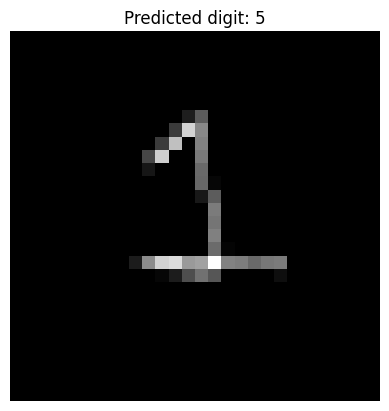

digit2.png | Predicted: 5 | Confidence: 20.33%


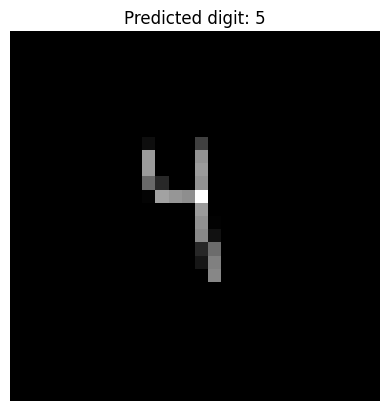

In [75]:
image_number = 1
custom_predictions = []
while True:
    image_path = DIGITS_DIR / f"digit{image_number}.png"
    if not image_path.is_file():
        break
    image = preprocess_digit(image_path)
    image_batch = np.expand_dims(image, axis=0)
    probabilities = model.predict(image_batch, verbose=0)[0]
    predicted_digit = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities))
    custom_predictions.append(predicted_digit)
    print(
        f"{image_path.name} | "
        f"Predicted: {predicted_digit} | "
        f"Confidence: {confidence:.2%}"
    )
    plt.imshow(image, cmap="gray")
    plt.title(f"Predicted digit: {predicted_digit}")
    plt.axis("off")
    plt.show()
    image_number += 1

In [76]:
print("Custom digit predictions:", custom_predictions)
print("Number of custom images:", len(custom_predictions))

Custom digit predictions: [5, 5]
Number of custom images: 2
